# 휴양지 위키백과 문서 조회수 EDA
`wiki_pageviews_monthly.csv`

    -출처: 위키피디아
    -목적: 해외 유명 휴양지 7곳에 대한 월별 관심도 분석
    -(휴양지 7곳 × 한국어/영어판, 2015-07~2026-09)

## 1. 기본 설정
운영체제에 맞춰 한글 폰트를 고릅니다. 그래프는 보고서에 쓸 수 있도록 PNG로도 저장합니다.

In [17]:
import os
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

system = platform.system()
if system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
else:
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

FILE = "wiki_pageviews_monthly.csv"
LANG_NAME = {"ko": "한국어판", "en": "영어판"}

## 2. 데이터 불러오기와 개요

In [18]:
df = pd.read_csv(FILE, encoding="utf-8-sig")
df["place"] = df["place"].str.split("_").str[0]        # 니스_(프랑스) → 니스
df["date"] = pd.to_datetime(df["month"])
df["year"] = df["date"].dt.year
df["m"] = df["date"].dt.month

print(df.shape)
print("기간:", df["month"].min(), "~", df["month"].max())
df[["place", "lang", "article"]].drop_duplicates()

(1890, 8)
기간: 2015-07 ~ 2026-09


,place,lang,article
0,제주도,ko,제주도
135,제주도,en,Jeju_Island
270,코타키나발루,ko,코타키나발루
405,코타키나발루,en,Kota_Kinabalu
540,니스,ko,니스_(프랑스)
675,니스,en,Nice
810,발리섬,ko,발리섬
945,발리섬,en,Bali
1080,괌,ko,괌
1215,괌,en,Guam


In [19]:
df.groupby(["place", "lang"]).size().unstack()   # 문서별 월 수 (모두 135개월이면 정상)

lang,en,ko
place,,
괌,135,135
니스,135,135
마이애미비치,135,135
발리섬,135,135
오키나와현,135,135
제주도,135,135
코타키나발루,135,135


## 3. 데이터 품질 점검
### 3-1. 결측치와 0

In [20]:
print(df.isna().sum())
df[df["views"] == 0]

place      0
lang       0
article    0
month      0
views      0
date       0
year       0
m          0
dtype: int64


,place,lang,article,month,views,date,year,m
811,발리섬,ko,발리섬,2015-08,0,2015-08-01,2015,8


### 3-2. 단절 구간 찾기
직전 12개월 중앙값보다 2.5배 이상 튄 달을 표시합니다. 몇 달 연속으로 튀면 사건보다는 **문서 제목 변경 같은 구조적 단절**일 가능성이 큽니다.

In [21]:
df = df.sort_values(["place", "lang", "date"])
df["med12"] = (df.groupby(["place", "lang"])["views"]
                 .transform(lambda x: x.rolling(12, min_periods=6).median().shift(1)))
df["배수"] = (df["views"] / df["med12"]).round(1)

jumps = df[df["배수"] >= 2.5][["place", "lang", "month", "views", "med12", "배수"]]
jumps

,place,lang,month,views,med12,배수
1240,괌,en,2017-08,1771681,137134.5,12.9
1105,괌,ko,2017-08,15630,3946.5,4.0
1174,괌,ko,2023-05,12109,4351.5,2.8
1177,괌,ko,2023-08,20780,4735.5,4.4
1178,괌,ko,2023-09,18095,4862.0,3.7
1179,괌,ko,2023-10,18195,5016.0,3.6
1180,괌,ko,2023-11,16178,5025.5,3.2
687,니스,en,2016-07,298351,60204.0,5.0
552,니스,ko,2016-07,2677,711.5,3.8
1421,마이애미비치,ko,2021-06,84,29.5,2.8


### 3-3. 정제
제목 변경으로 보이는 구간을 분석에서 제외합니다(값을 NaN으로). 원본은 `views_raw`에 남겨 둡니다.

In [22]:
# ① 제목 변경으로 인한 단절 구간 제외 (기존과 동일)
EXCLUDE = [
    ("발리섬", "ko", "2017-05"),      # 이 달까지 제외
    ("오키나와현", "ko", "2017-12"),
    ("제주도", "en", "2017-02"),
]

df["views_raw"] = df["views"]
for place, lang, until in EXCLUDE:
    mask = (df["place"] == place) & (df["lang"] == lang) & (df["month"] <= until)
    df.loc[mask, "views"] = np.nan

# ② 이상치 탐지: 같은 문서의 다른 연도 같은 달 중앙값과 비교
THRESHOLD = 2.5   # 같은 달 중앙값의 2.5배 이상이면 이상치

df["같은달중앙값"] = df.groupby(["place", "lang", "m"])["views"].transform("median")
df["같은달배수"] = (df["views"] / df["같은달중앙값"]).round(1)
outlier = df["같은달배수"] >= THRESHOLD

# ③ 이상치를 같은 달 중앙값으로 치환한 분석용 컬럼 만들기
df["views_clean"] = df["views"].where(~outlier, df["같은달중앙값"])

print("제목 변경 제외:", df["views"].isna().sum(), "개월")
print("이상치 치환:", outlier.sum(), "개월")
df.loc[outlier, ["place", "lang", "month", "views", "views_clean", "같은달배수"]]

제목 변경 제외: 73 개월
이상치 치환: 59 개월


,place,lang,month,views,views_clean,같은달배수
1240,괌,en,2017-08,1771681.0,125515.0,14.1
1080,괌,ko,2015-07,13983.0,5002.5,2.8
1081,괌,ko,2015-08,13205.0,5019.5,2.6
1086,괌,ko,2016-01,12549.0,5115.0,2.5
1089,괌,ko,2016-04,14417.0,4146.0,3.5
1105,괌,ko,2017-08,15630.0,5019.5,3.1
1174,괌,ko,2023-05,12109.0,4111.0,2.9
1177,괌,ko,2023-08,20780.0,5019.5,4.1
1178,괌,ko,2023-09,18095.0,4367.0,4.1
1179,괌,ko,2023-10,18195.0,5064.0,3.6


## 4. 휴양지별 관심도 규모
코로나 이후 정상화된 2022~2025년(48개월) 기준입니다.

In [23]:
recent = df[df["year"].between(2022, 2025)]
scale = recent.pivot_table(index="place", columns="lang", values="views_clean", aggfunc="mean").round()
scale["한국어/영어(%)"] = (scale["ko"] / scale["en"] * 100).round(1)
scale = scale.rename(columns={"ko": "한국어판 월평균", "en": "영어판 월평균"})
scale = scale.sort_values("영어판 월평균", ascending=False)
scale

lang,영어판 월평균,한국어판 월평균,한국어/영어(%)
place,,,
발리섬,146201.0,1412.0,1.0
괌,121716.0,5815.0,4.8
니스,56488.0,715.0,1.3
오키나와현,39496.0,2531.0,6.4
제주도,39390.0,3910.0,9.9
마이애미비치,16987.0,34.0,0.2
코타키나발루,13567.0,1663.0,12.3


## 5. 월별 추이
휴양지마다 작은 그래프로 나눠 한국어판과 영어판을 겹쳐 그립니다. 규모 차이가 커서 로그 스케일을 쓰고, 코로나19 기간(2020-03~2022-06)을 음영으로 표시합니다.

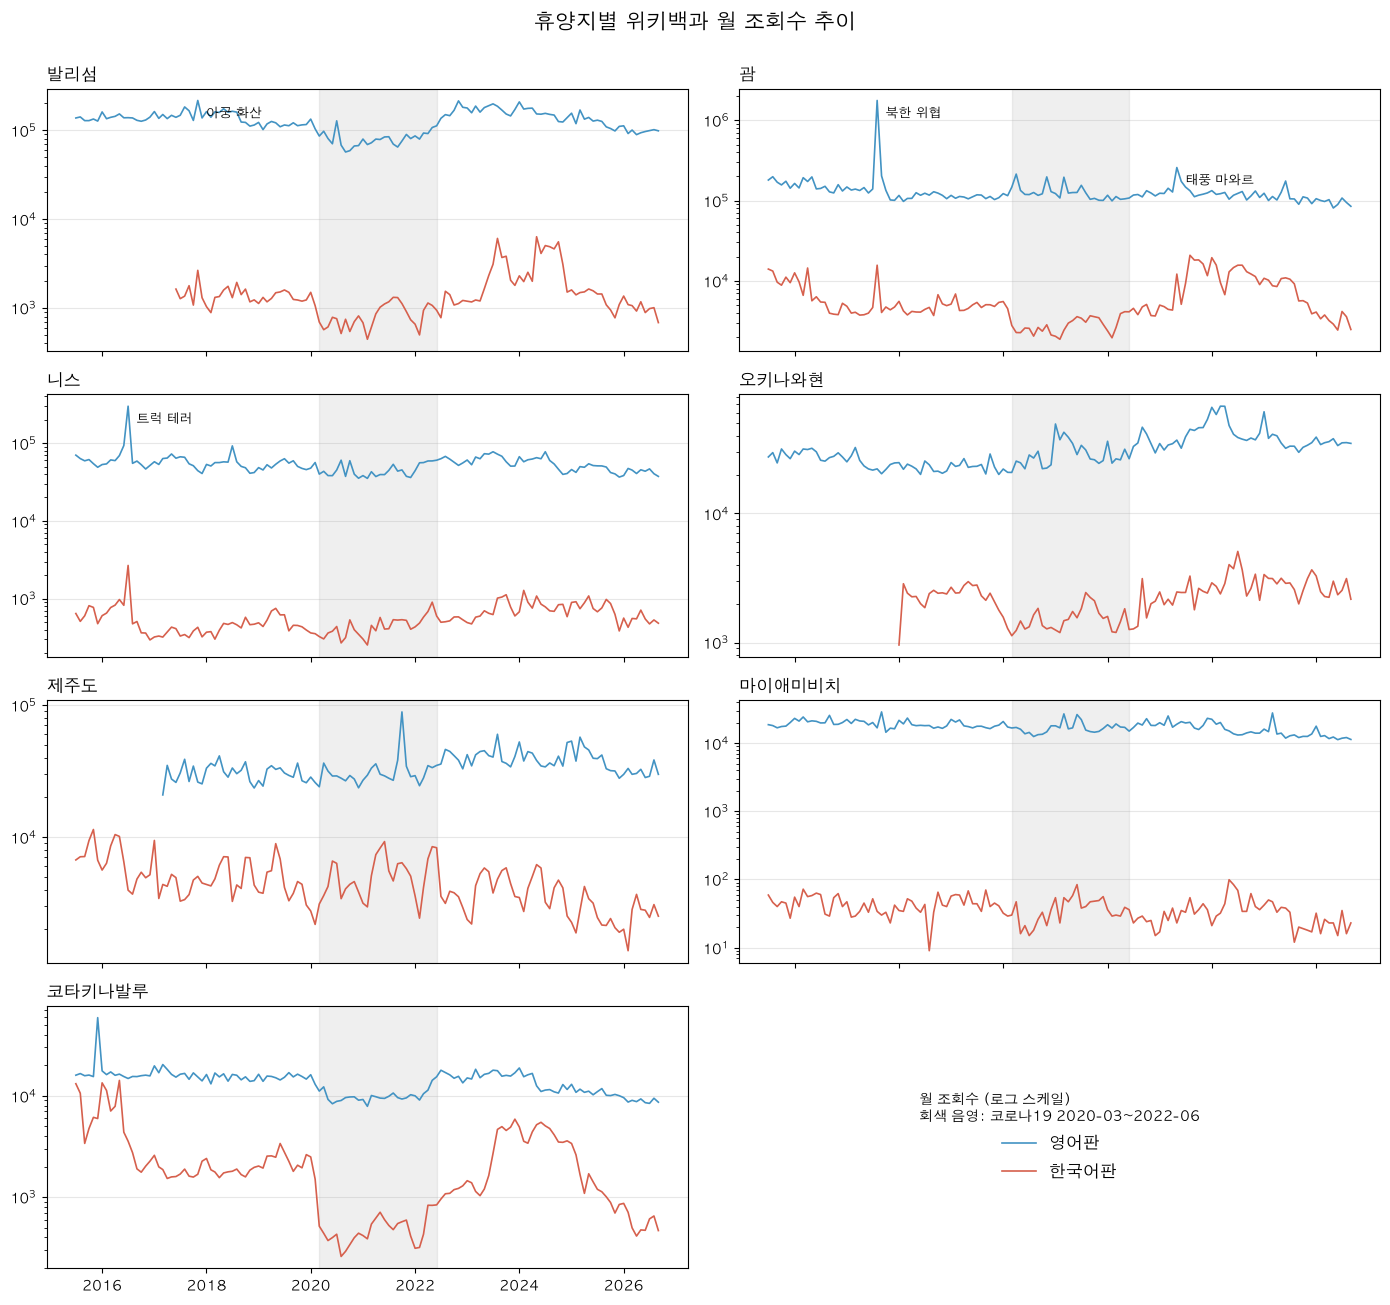

In [24]:
EVENTS = {   # 영어판 급등 (원인은 추정, 검증 필요)
    ("니스", "2016-07"): "트럭 테러",
    ("괌", "2017-08"): "북한 위협",
    ("발리섬", "2017-11"): "아궁 화산",
    ("괌", "2023-05"): "태풍 마와르",
}
COLORS = {"ko": "#d6604d", "en": "#4393c3"}
places = scale.index   # 영어판 규모 순

fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True)
for ax, place in zip(axes.flat, places):
    for lang in ["en", "ko"]:
        s = df[(df["place"] == place) & (df["lang"] == lang)].set_index("date")["views"]
        ax.plot(s.index, s, color=COLORS[lang], linewidth=1.2, label=LANG_NAME[lang])
    ax.set_yscale("log")
    ax.axvspan(pd.Timestamp("2020-03"), pd.Timestamp("2022-06"), color="gray", alpha=0.12)
    ax.set_title(place, loc="left", fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
    for (ev_place, month), label in EVENTS.items():
        if ev_place == place:
            y = df[(df["place"] == place) & (df["lang"] == "en") & (df["month"] == month)]["views"].iloc[0]
            ax.annotate(label, (pd.Timestamp(month), y), xytext=(6, -4),
                        textcoords="offset points", fontsize=9, va="top")

axes.flat[-1].axis("off")
axes.flat[-2].tick_params(labelbottom=True)   # 오른쪽 열에도 연도 표시
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", fontsize=12, frameon=False,
                     title="월 조회수 (로그 스케일)\n회색 음영: 코로나19 2020-03~2022-06")
fig.suptitle("휴양지별 위키백과 월 조회수 추이", fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig("fig_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. 계절성
해마다 규모가 달라지는 영향을 없애기 위해, **연도별로** 월평균을 1로 맞춘 뒤 2022~2025년 같은 달을 평균 냅니다. 1보다 크면 그 해 평균보다 관심이 높은 달입니다.

In [25]:
recent = df[df["year"].between(2022, 2025)].copy()
recent["ratio"] = recent["views_clean"] / recent.groupby(["place", "lang", "year"])["views_clean"].transform("mean")
seasonal = recent.groupby(["lang", "place", "m"])["ratio"].mean().unstack("m")

summary = pd.DataFrame({
    "최고 달": seasonal.idxmax(axis=1),
    "최저 달": seasonal.idxmin(axis=1),
    "진폭": (seasonal.max(axis=1) - seasonal.min(axis=1)).round(2),
})
summary

최고 달  최저 달    진폭
lang place                   
en   괌          5     9  0.33
     니스         7    11  0.38
     마이애미비치     3     6  0.49
     발리섬        3     2  0.17
     오키나와현      1     6  0.42
     제주도        8     2  0.32
     코타키나발루     8     2  0.14
ko   괌          7     5  0.51
     니스         5    12  0.57
     마이애미비치     6    12  0.62
     발리섬        7    10  0.35
     오키나와현      5     3  0.26
     제주도        5     2  0.90
     코타키나발루     1     4  0.66

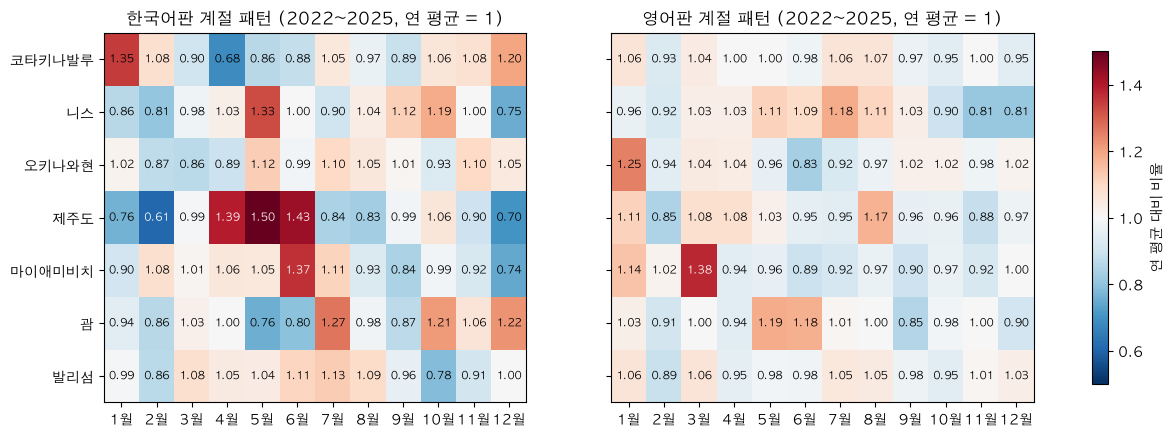

In [26]:
order = seasonal.loc["ko"].idxmax(axis=1).sort_values().index   # 한국어판 최고 달 순서로 정렬

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, lang in zip(axes, ["ko", "en"]):
    data = seasonal.loc[lang].loc[order]
    im = ax.imshow(data, cmap="RdBu_r", vmin=0.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(12), [f"{m}월" for m in range(1, 13)])
    ax.set_yticks(range(len(order)), order)
    for i in range(len(order)):
        for j in range(12):
            v = data.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(v - 1) > 0.35 else "black")
    ax.set_title(f"{LANG_NAME[lang]} 계절 패턴 (2022~2025, 연 평균 = 1)")
fig.colorbar(im, ax=axes, label="연 평균 대비 비율", shrink=0.9)
plt.savefig("fig_seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. 한국어판과 영어판 비교
### 7-1. 계절 패턴 상관계수

In [27]:
corr = {p: np.corrcoef(seasonal.loc[("ko", p)], seasonal.loc[("en", p)])[0, 1]
        for p in seasonal.loc["ko"].index}
pd.Series(corr, name="상관계수").round(2).sort_values()

괌        -0.40
마이애미비치   -0.15
오키나와현    -0.13
코타키나발루    0.08
제주도       0.17
니스        0.35
발리섬       0.58
Name: 상관계수, dtype: float64

### 7-2. 코로나19 충격과 회복 (2019년 대비 증감률)

In [28]:
yearly = df.pivot_table(index="place", columns=["lang", "year"], values="views_clean", aggfunc="sum")
covid = pd.DataFrame({
    f"2020 vs 2019 ({lang})": (yearly[(lang, 2020)] / yearly[(lang, 2019)] - 1) * 100
    for lang in ["ko", "en"]
} | {
    f"2023 vs 2019 ({lang})": (yearly[(lang, 2023)] / yearly[(lang, 2019)] - 1) * 100
    for lang in ["ko", "en"]
}).round(0)
covid

,2020 vs 2019 (ko),2020 vs 2019 (en),2023 vs 2019 (ko),2023 vs 2019 (en)
place,,,,
괌,-43.0,25.0,12.0,28.0
니스,-30.0,-14.0,39.0,22.0
마이애미비치,-46.0,-15.0,-33.0,6.0
발리섬,-41.0,-27.0,24.0,49.0
오키나와현,-43.0,2.0,-3.0,69.0
제주도,-15.0,-6.0,-7.0,38.0
코타키나발루,-72.0,-32.0,-30.0,6.0


## 8. 저장

In [29]:
df.to_csv("pageviews_clean.csv", index=False, encoding="utf-8-sig")
scale.to_csv("eda_scale.csv", encoding="utf-8-sig")
seasonal.round(3).to_csv("eda_seasonality.csv", encoding="utf-8-sig")
covid.to_csv("eda_covid.csv", encoding="utf-8-sig")
print(os.path.abspath("pageviews_clean.csv"))

/Users/song-uihyeok/Desktop/github_with claude code/wiki_pageviews/pageviews_clean.csv


# wikipidia 유명 휴양지 검색자 수 — 수집 리포트

## 1. 페이지 판별
- 정적/동적: 정적 (근거: requests로 받은 HTML 소스의 브라우저 화면과 내용이 동일하다)
- 선택한 도구: requests + Wikumedia Pageviews Api(HSON), 제목확인에 BeautifulSuop (이유: API를 이용했고 정적페이지라 selemium을 사용하지 않음)

## 2. 수집 (AI 보조 4단계)
- 목적: 휴양지 7곳의 한국어판과 영어판 위키백과 문서 월별 조회수를 통해 관심이 많아진 월을 분석
- AI 초안 검증 결과: API는 문서 제목이 정확해야함 -> 문서 제목 불일치
- 수정: 제목 교정후, 최종 1890행 수집

## 3. 정제 (재적용한 랭글링)
- 이름 정리: place의 니스_(프랑스) → 니스 (str.split("_")) / 날짜 변환: month 문자열 → datetime, 연도·월 컬럼 파생
- 결측 처리: 원본 결측 0건, 조회수 0은 1건. 문서 제목 변경으로 값이 비정상적으로 작은 단절 구간 3곳 73개월은 NaN 처리해 분석에서 제외
- 이상치 처리: 특정 사건에 의해 지난 데이터 중앙값에 비해 많은 조회수(13배,7.9배 등)은 중앙값으로 치환 -> 특정 사건에 의해 관심도 증가로 판단

## 4. 윤리 검토
- robots.txt: ko.wikipedia.org의 User-agent: * 규칙에서 /wiki/ 일반 문서는 수집 가능, /w/·/api/·특수: 페이지·초안: 문서는 Disallow. Crawl-delay는 없음 (SemrushBot에만 5초). 주석은 "천천히 요청하는 봇의 문서 열람은 환영, 동적 생성 페이지는 자제"를 요청
- 조회수 API: wikimedia.org라는 별도 호스트라 위 robots.txt의 적용 대상이 아니며, 위키미디어의 API 이용 정책(User-Agent 명시, 적정 속도)을 따름
• 요청 예의: 요청 사이 time.sleep(1), 프로젝트명과 연락처를 넣은 User-Agent, 429 응답 시 대기 후 재시도를 적용
- 개인정보: 월별 집계 수치뿐이라 개인을 식별할 정보는 없음


## 5. 다음 단계
- 휴양지별 조회수 증가시기 분석(한국어판, 영어판)

| 휴양지 | 한국어판 조회수 증가 달 | 영어판 조회수 증가 달 |
| --- | --- | --- |
| 제주도 | 5월(1.50), 6월(1.43), 4월(1.39) | 8월(1.17), 1월(1.11) |
| 괌 | 7월(1.27), 12월(1.22), 10월(1.21) | 5월(1.19), 6월(1.18) |
| 코타키나발루 | 1월(1.32), 8월(1.30), 12월(1.16) | 뚜렷한 증가 달 없음 |
| 발리섬 | 7월(1.13), 6월(1.11) | 뚜렷한 증가 달 없음 |
| 오키나와현 | 5월(1.12), 7월(1.10), 11월(1.10) | 1월(1.25) |
| 니스 | 5월(1.33), 10월(1.19), 9월(1.12) | 7월(1.18), 5월(1.11), 8월(1.11) |
| 마이애미비치 | 6월(1.37), 7월(1.11) | 3월(1.38), 1월(1.14) |

**해석**

- 한국어판은 방학·휴가철에 맞춰 움직인다. 제주도는 4~6월 여름 여행 준비 시즌에 몰리고, 코타키나발루는 겨울방학(12~1월)과 여름휴가(8월)에 두 번 정점을 찍는다.
- 괌과 발리섬은 여름휴가를 앞둔 6~7월에, 니스는 유럽 여행 성수기인 5월과 가을(9~10월)에 관심이 높다.
- 영어판은 계절 변화가 전반적으로 작지만, 마이애미비치 3월(미국 봄방학)과 니스 7~8월(유럽 여름휴가)처럼 영어권 휴가 시즌을 따르는 경우가 있다.
- 한국어판은 날씨의 영향이 있어보인다. 장마나 태풍, 건기 시즌에 맞춰 관심도가 증가하였다. 하지만 괌과 코타키나발루의 경우에는 우기 시즌에 조회수가 높았다.

**주의할 점**

- 치환 전 데이터에서는 괌·발리섬 한국어판이 8월에 가장 높았다. 치환 후 정점이 7월로 옮겨간 것은 2023~2024년 장기 상승 구간의 여름 달들이 중앙값으로 바뀌었기 때문이다. 일별 데이터로 확인하기 전까지 괌·발리섬·코타키나발루 한국어판은 "6~8월 여름휴가 시즌"처럼 범위로 해석한다.
